# EDA: OEWS Occupation Panel (2015-2025)

Exploratory analysis of the annual occupation-level employment/wage panel built by `data/fetch_oews.py` and `src/build_features.py`. See `docs/METHODOLOGY.md` for why this is annual (not monthly).


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
df = pd.read_csv("../data/processed/oews_occupation_features.csv")
print(f"{len(df):,} rows, {df['occ_code'].nunique()} unique occupation codes, years {df['year'].min()}-{df['year'].max()}")
df.head()


8,988 rows, 965 unique occupation codes, years 2015-2025


,year,occ_code,occ_title,employment_level,wage_hourly_mean,wage_annual_mean,wage_hourly_median,wage_annual_median,wage_annual_pct10,wage_annual_pct90,employment_prse,wage_annual_mean_prse,employment_change_yoy_pct,wage_growth_yoy_pct,employment_change_5yr_cagr,wage_growth_5yr_cagr,contraction_flag_12mo,wage_annual_mean_real,real_wage_growth_yoy_pct,purchasing_power_loss_flag,jolts_exposure_openings_rate,jolts_exposure_quits_rate,jolts_exposure_layoffs_rate
0,2015,11-1011,Chief Executives,242560.0,97.62,203050.0,83.45,173570.0,70120.0,NaN,1.0,0.5,NaN,NaN,NaN,NaN,NaN,274483.161624,NaN,NaN,4.002240,1.905161,1.307914
1,2016,11-1011,Chief Executives,213280.0,102.50,213200.0,89.46,186080.0,73710.0,NaN,0.8,0.6,-12.071240,4.998769,NaN,NaN,1.0,285295.855205,3.939292,0.0,4.144092,1.994984,1.284745
2,2017,11-1011,Chief Executives,200260.0,99.56,207090.0,88.88,184880.0,67830.0,NaN,0.9,0.7,-6.104651,-2.865854,NaN,NaN,1.0,272019.657545,-4.653484,0.0,4.139215,2.101205,1.261587
3,2018,11-1011,Chief Executives,186640.0,100.33,208690.0,89.42,185990.0,70200.0,NaN,0.9,0.6,-6.801158,0.772611,NaN,NaN,1.0,266652.347687,-1.973133,1.0,4.644186,2.156747,1.236615
4,2019,11-1011,Chief Executives,209620.0,99.53,207010.0,88.85,184800.0,58310.0,NaN,1.4,0.6,12.312473,-0.805022,NaN,NaN,0.0,259853.762125,-2.549606,0.0,4.667504,2.204257,1.259620


## Employment size distribution

Occupation employment is heavily right-skewed: a handful of occupations employ millions of people while the median occupation employs a few thousand. So an unweighted median describes the typical occupation, not the typical worker.

count    8.300000e+02
mean     1.873275e+05
std      4.489514e+05
min      2.200000e+02
25%      1.408500e+04
50%      4.270500e+04
75%      1.489975e+05
max      4.305810e+06
Name: employment_level, dtype: float64


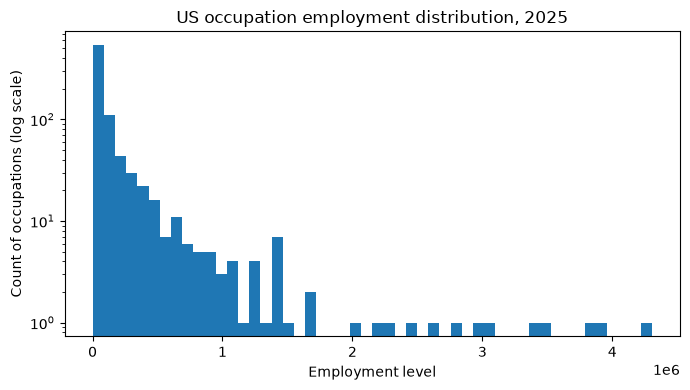

In [2]:
latest = df[df["year"] == df["year"].max()]
print(latest["employment_level"].describe())

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(latest["employment_level"].dropna(), bins=50, log=True)
ax.set_xlabel("Employment level")
ax.set_ylabel("Count of occupations (log scale)")
ax.set_title(f"US occupation employment distribution, {int(latest['year'].iloc[0])}")
plt.tight_layout()
plt.show()


## Wage distribution (nominal)

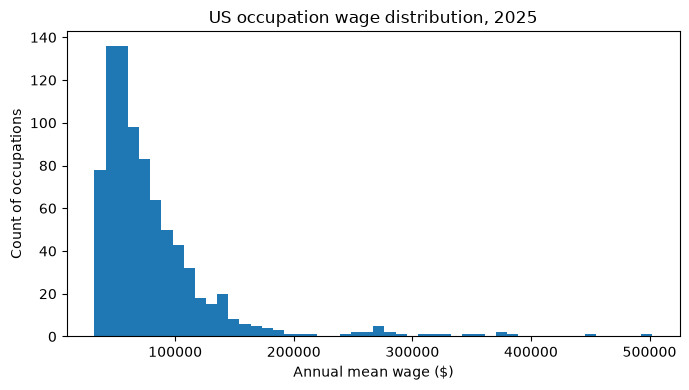

count       825.000000
mean      80229.393939
std       51692.972444
min       31980.000000
25%       50200.000000
50%       66370.000000
75%       91550.000000
max      502050.000000
Name: wage_annual_mean, dtype: float64


In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(latest["wage_annual_mean"].dropna(), bins=50)
ax.set_xlabel("Annual mean wage ($)")
ax.set_ylabel("Count of occupations")
ax.set_title(f"US occupation wage distribution, {int(latest['year'].iloc[0])}")
plt.tight_layout()
plt.show()

print(latest["wage_annual_mean"].describe())


## Top 10 contracting and top 10 growing US occupations (most recent year)

Note: these tables rank by raw percentage change with no employment floor, so small occupations dominate the extremes (OEWS sampling noise). The dashboard's sector tab applies a 500-employee floor (in both years compared) to its ranked tables.

In [4]:
us_latest = latest.dropna(subset=["employment_change_yoy_pct"])
cols = ["occ_title", "employment_level", "employment_change_yoy_pct", "wage_growth_yoy_pct"]
print("Top 10 contracting:")
display(us_latest.nsmallest(10, "employment_change_yoy_pct")[cols])
print("\nTop 10 growing:")
display(us_latest.nlargest(10, "employment_change_yoy_pct")[cols])


Top 10 contracting:


,occ_title,employment_level,employment_change_yoy_pct,wage_growth_yoy_pct
5296,"Door-to-Door Sales Workers, News and Street Ve...",2760.0,-39.869281,9.927300
5461,Correspondence Clerks,4290.0,-31.469649,3.175284
8928,Gas Compressor and Gas Pumping Station Operators,3510.0,-31.311155,3.986063
4938,"Makeup Artists, Theatrical and Performance",2340.0,-29.518072,35.578836
5241,Models,3780.0,-29.345794,-10.718666
1759,"Geological Technicians, Except Hydrologic Tech...",6980.0,-28.115345,6.269323
5997,"Agricultural Workers, All Other",3620.0,-27.309237,-0.589777
8677,"Rail Transportation Workers, All Other",1120.0,-26.315789,12.411215
3663,"Ophthalmologists, Except Pediatric",8950.0,-26.094137,1.044776
1607,Industrial-Organizational Psychologists,790.0,-24.761905,26.659226



Top 10 growing:


,occ_title,employment_level,employment_change_yoy_pct,wage_growth_yoy_pct
8594,Taxi Drivers,41050.0,134.437464,27.016026
440,"Insurance Appraisers, Auto Damage",11560.0,48.395379,2.401038
4323,Transit and Railroad Police,4390.0,46.333333,-0.010891
2976,Actors,55000.0,41.752577,NaN
3620,Neurologists,10590.0,37.532468,-6.524397
1480,Astronomers,2120.0,35.897436,-1.123261
2028,"Religious Workers, All Other",15760.0,29.498767,8.107566
1348,Animal Scientists,3100.0,25.506073,-15.833095
1244,Aerospace Engineering and Operations Technolog...,11280.0,24.503311,5.768562
8803,"Transportation Workers, All Other",13550.0,23.631387,12.988455


## Employment trend, selected occupations

A few of the largest occupations, national employment over time.

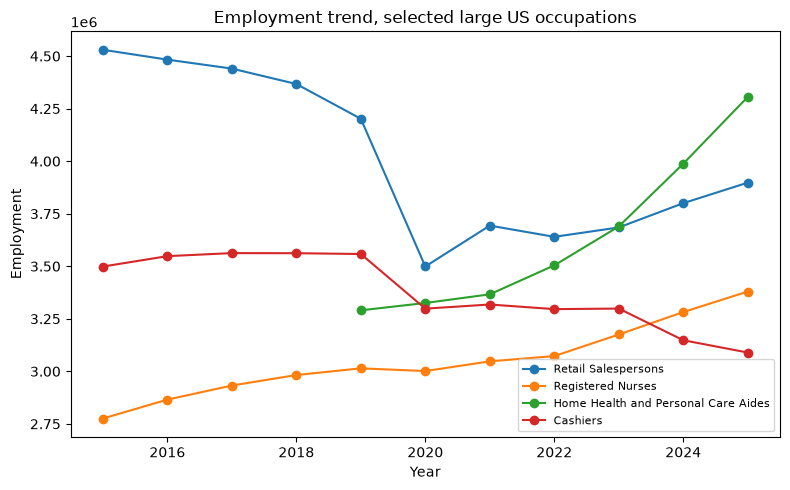

In [5]:
occupations_of_interest = ["Retail Salespersons", "Registered Nurses", "Home Health and Personal Care Aides", "Cashiers"]
fig, ax = plt.subplots(figsize=(8, 5))
for title in occupations_of_interest:
    sub = df[df["occ_title"] == title].sort_values("year")
    if sub.empty:
        continue
    ax.plot(sub["year"], sub["employment_level"], marker="o", label=title)
ax.set_xlabel("Year")
ax.set_ylabel("Employment")
ax.set_title("Employment trend, selected large US occupations")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## Real wages: did pay keep up with prices?

Each year's wages are deflated with that year's May CPI-U (see `docs/METHODOLOGY.md#cpi-and-jolts`) and expressed in 2025 dollars. The chart shows the share of occupations whose *real* wage fell, next to the share whose *nominal* wage fell.

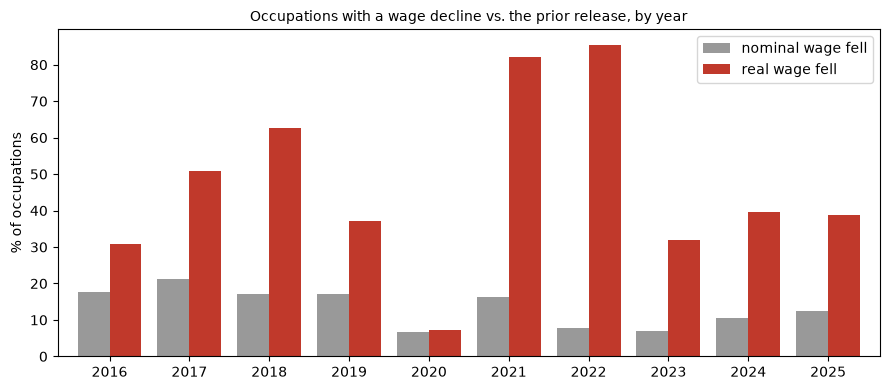

2015 -> 2025, 713 occupations present in both years: median real wage change +1.0%, 45% ended lower


In [6]:
us = df
share = pd.DataFrame({
    "nominal wage fell": us["wage_growth_yoy_pct"].dropna().lt(0).groupby(us["year"]).mean() * 100,
    "real wage fell": us["real_wage_growth_yoy_pct"].dropna().lt(0).groupby(us["year"]).mean() * 100,
}).dropna()
ax = share.plot(kind="bar", figsize=(9, 4), color=["#999999", "#c0392b"], width=0.8)
ax.set_ylabel("% of occupations"); ax.set_xlabel("")
ax.set_title("Occupations with a wage decline vs. the prior release, by year", fontsize=10)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

first, last = df["year"].min(), df["year"].max()
span = us.pivot(index="occ_code", columns="year", values="wage_annual_mean_real").dropna(subset=[first, last])
change = (span[last] / span[first] - 1) * 100
print(f"{first} -> {last}, {len(change)} occupations present in both years: median real wage change {change.median():+.1f}%, "
      f"{(change < 0).mean():.0%} ended lower")